# Exercise: Mapping Model Explanations
## GeoAI & Geovisualization — Explainability on Maps

**Goal:** train a simple spatial prediction model, extract feature contributions, and render them using four map types, drawn **on a basemap of Salzburg**:
1. Proportional symbol map (two variants: 1a continuous diverging colour, 1b size = magnitude, colour = direction)
2. Choropleth (aggregated) map
3. "Attribution surface" (interpolated heatmap, stand-in for saliency/Grad-CAM)
4. Uncertainty-aware map (confidence encoded alongside the prediction)

**Scenario:** synthetic bike-share demand at 400 locations scattered around Salzburg's city center, predicted from four features: distance to center, green-space fraction, population density, and transit access. The demand values, features, and model are entirely synthetic — only the geography (Salzburg) is real.

Notes:
>> This exercise is inspired by recent work on GeoXAI (Geospatial eXplainable AI), which argues that standard XAI outputs — SHAP values, feature attributions — lose their meaning when stripped of geographic context, and need dedicated geovisualization techniques rather than generic plots.

>> Specifically, the four map types built in this notebook (proportional symbols, choropleth aggregation, interpolated surfaces, and confidence-aware maps) follow the visualization concepts proposed for mapping Shapley values in geospatial machine learning:

- Roussel, C. (2024). Visualization of explainable artificial intelligence for GeoAI. Frontiers in Computer Science, 6, 1414923. https://doi.org/10.3389/fcomp.2024.1414923

- Roussel, C., & Böhm, K. (2023). Geospatial XAI: A review. ISPRS International Journal of Geo-Information, 12(9), 355. https://doi.org/10.3390/ijgi12090355

The synthetic Salzburg bike-share scenario, the RandomForest model, and the specific figures in this notebook are original teaching material built for this course — they are not taken from the papers above. The papers are cited because the underlying idea (visualize per-location feature attributions using multiple map types rather than a single generic plot, since geographic aggregation and interpolation change what a viewer perceives) is drawn directly from that line of research.

>> **Internet access is required** for this notebook (tile downloads for the basemap). Run `pip install contextily geopandas` first if these aren't already installed.
>> **Note:** the default basemap is Esri World Gray Canvas, which is free and requires no API key.

## 1. Setup

In [6]:
import os  # Read the user's home folder for the tile cache.
import numpy as np  # Create and calculate numeric arrays.
import pandas as pd  # Group observations into grid cells.
import geopandas as gpd  # Store and reproject spatial data.
import contextily as ctx  # Add a web basemap to plots.
import matplotlib.pyplot as plt  # Create the figures.
from matplotlib.colors import ListedColormap, LinearSegmentedColormap, Normalize  # Create readable color scales.
from scipy.interpolate import griddata  # Interpolate point values to a surface.
from shapely.geometry import Point, box  # Create point and rectangle geometries.
from sklearn.ensemble import RandomForestRegressor  # Train the prediction model.

try:  # Use SHAP when it is installed.
    import shap  # Calculate tree-model feature contributions.
    HAS_SHAP = True  # Record that SHAP is available.
except ImportError:  # Keep the exercise runnable without SHAP.
    HAS_SHAP = False  # Use the simple fallback contribution instead.

def fallback_contribution(model, X, feature):
    """Mean-baseline contribution: prediction change when `feature` is replaced by its mean."""
    X_base = X.copy()  # Keep the original features untouched.
    X_base[feature] = X[feature].mean()  # Neutralise one feature.
    return model.predict(X) - model.predict(X_base)  # Positive = feature raises the prediction.

# Basemap provider (all keyless). CARTO basemaps now need a free API key, otherwise tiles show a watermark.
BASEMAP_SOURCE = ctx.providers.Esri.WorldGrayCanvas  # Muted grey, good under bold colour overlays.
# BASEMAP_SOURCE = ctx.providers.Esri.WorldStreetMap  # Detailed street map.
# BASEMAP_SOURCE = ctx.providers.OpenStreetMap.HOT    # Humanitarian OSM tiles.
# BASEMAP_SOURCE = ctx.providers.OpenTopoMap          # Terrain/relief.
# CARTO Positron with a free key (https://carto.com/basemaps/apikey):
# BASEMAP_SOURCE = ctx.providers.CartoDB.Positron(apikey="your_api_key_here")

blue_cmap = ListedColormap(plt.cm.Blues(np.linspace(0.25, 1, 256)))  # Start blue gradients at light blue - not at white.
green_cmap = ListedColormap(plt.cm.Greens(np.linspace(0.25, 1, 256)))  # Start green gradients at light green - not at white.
ctx.set_cache_dir(os.path.expanduser("~/contextily_cache"))  # Cache downloaded tiles.
print("SHAP available:", HAS_SHAP)  # Show which contribution method will run.

SHAP available: True


## 2. Generate a synthetic dataset around Salzburg

Locations are scattered in a box of roughly 5.6 × 5.2 km around Salzburg's city center (47.8095° N, 13.0550° E), i.e. up to ~3.7 km from the center. We first build the GeoDataFrame in WGS84 (EPSG:4326) — the standard latitude/longitude system GPS and most raw datasets use. Distances to the center are measured in a metric CRS (UTM zone 33N, EPSG:32633), and only then is the data reprojected to Web Mercator (EPSG:3857) for plotting.

***Why we reproject:***

- _WGS84 is a geographic CRS: coordinates are angular degrees on a sphere/ellipsoid, not flat-plane distances. You can't directly overlay them, pixel-for-pixel, on a flat raster image._
- _Nearly every web basemap provider (Esri, OpenStreetMap, CARTO, Google, Mapbox, and `contextily` here) pre-renders its tiles in Web Mercator, a projected CRS measured in meters on a flat plane. That's simply the shared standard the whole web-mapping ecosystem settled on._
- _So "reprojecting" means mathematically transforming each point's coordinates from angular degrees (WGS84) into planar meters (Web Mercator), using the same projection formula the tile server used to render its images. Without this step, our points and the basemap would use different, incompatible coordinate systems — `ctx.add_basemap()` would place the tiles correctly, but our scattered points (still in degrees) would either not line up with the streets and landmarks underneath them, or could fail to appear in the plotted extent at all._

***Why we do NOT measure distances in Web Mercator:***

- _Web Mercator preserves local shape, so a city map looks right, but its "meters" are stretched by 1/cos(latitude). At Salzburg (~47.8° N) that is a factor of ~1.49: a true 2 km distance would be measured as ~3 km._
- _So Web Mercator is fine for display, but distances and areas must be computed in an equal-distance-friendly local CRS such as UTM 33N (EPSG:32633) or Austria's MGI / Gauß-Krüger M31 (EPSG:31258)._

In [7]:
np.random.seed(42)  # Make the random dataset reproducible.
n = 400  # Create 400 locations.
center_lat, center_lon = 47.8095, 13.0550  # Set Salzburg city center.
lat = center_lat + np.random.uniform(-0.025, 0.025, n)  # Generate latitudes.
lon = center_lon + np.random.uniform(-0.035, 0.035, n)  # Generate longitudes.

points = [Point(x, y) for x, y in zip(lon, lat)]  # Turn coordinates into points.
gdf = gpd.GeoDataFrame({"lat": lat, "lon": lon}, geometry=points, crs="EPSG:4326")  # Store WGS84 data.

center_utm = gpd.GeoSeries([Point(center_lon, center_lat)], crs="EPSG:4326").to_crs(epsg=32633).iloc[0]  # Center in UTM 33N.
gdf["dist_center_km"] = gdf.to_crs(epsg=32633).geometry.distance(center_utm) / 1000  # True distance in km (metric CRS).
gdf = gdf.to_crs(epsg=3857)  # Reproject to the basemap's coordinate system for plotting only.

gdf["green_frac"] = np.clip(np.random.normal(0.3, 0.15, n), 0, 1)  # Simulate green-space fraction.
gdf["pop_density"] = np.clip(120 * np.exp(-0.5 * gdf["dist_center_km"]) + np.random.normal(0, 5, n), 0, None)  # Simulate population density.
gdf["transit_access"] = np.clip(1 - gdf["dist_center_km"] / 3 + np.random.normal(0, 0.1, n), 0, 1)  # Simulate transit access.
gdf["demand"] = np.clip(0.6 * gdf["pop_density"] - 20 * gdf["dist_center_km"] + 40 * gdf["green_frac"] + 30 * gdf["transit_access"] + np.random.normal(0, 8, n), 0, None)  # Simulate bike demand.

# Each term has a sign that encodes whether that feature should increase or decrease predicted demand:
# +0.6 * pop_density — more people nearby → more potential riders → higher demand.
# -20 * dist_center_km — this is the key one. As a location gets farther from the city center, bike-share demand drops.
#   City centers concentrate destinations, transit hubs, and foot traffic, while the outskirts don't.
#   This term alone subtracts 20 units per extra kilometer; because pop_density and transit_access also fall
#   with distance, the total drop in demand per kilometer is larger than 20.
# +40 * green_frac — more green space nearby → higher demand (people like cycling near parks).
# +30 * transit_access — better transit access → higher demand (bike-share often complements public transit).

feats = ["dist_center_km", "green_frac", "pop_density", "transit_access"]  # List the model inputs.
gdf.head()  # Preview the first locations.

,lat,lon,geometry,dist_center_km,green_frac,pop_density,transit_access,demand
0,47.803227,13.027219,POINT (1450183.349 6074181.029),2.194416,0.181429,42.670382,0.322358,0.000000
1,47.832036,13.083179,POINT (1456412.791 6078956.913),3.275352,0.370720,20.463260,0.015467,0.000000
2,47.821100,13.055368,POINT (1453316.881 6077143.637),1.289846,0.582304,62.842572,0.533556,49.408596
3,47.814433,13.077852,POINT (1455819.828 6076038.422),1.797007,0.501813,59.572788,0.317077,24.188347
4,47.792301,13.042403,POINT (1451873.713 6072370.406),2.132157,0.538978,49.960472,0.184800,15.785510


## 3. Map the synthetic demand

Before training a model, inspect the synthetic demand that we created. Darker green points represent higher demand.

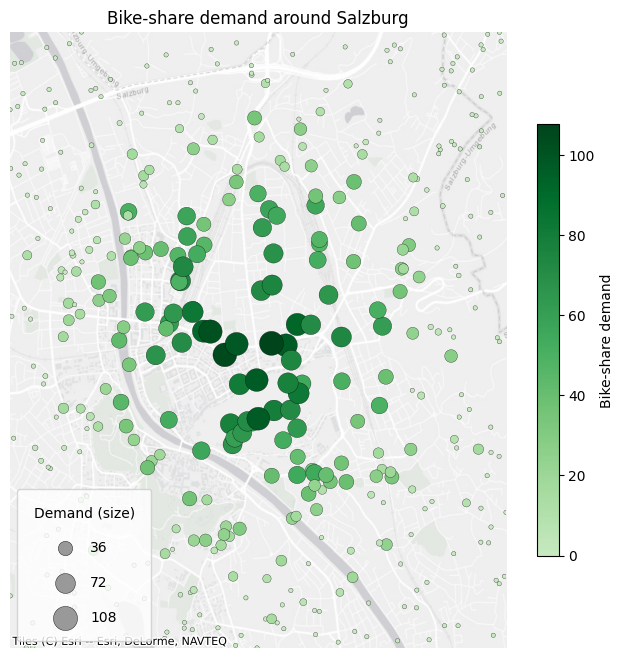

In [8]:
xs, ys = gdf.geometry.x, gdf.geometry.y  # Extract projected coordinates.

fig, ax = plt.subplots(figsize=(8, 8))  # Create a square map.
map_xlim = (xs.min(), xs.max())  # Use the same horizontal extent as later maps.
map_ylim = (ys.min(), ys.max())  # Use the same vertical extent as later maps.
demand_vmin, demand_vmax = gdf["demand"].min(), gdf["demand"].max()  # Fix the demand color interval.

# Proportional symbols: marker AREA also scales with demand, reinforcing the color encoding.
size_min, size_max = 10, 300  # Smallest and largest marker areas, in points^2.
def size_for(demand):
    return size_min + (size_max - size_min) * (demand - demand_vmin) / (demand_vmax - demand_vmin)  # Linear area scaling.

sc = ax.scatter(gdf.geometry.x, gdf.geometry.y, c=gdf["demand"], cmap=green_cmap, vmin=demand_vmin, vmax=demand_vmax, s=size_for(gdf["demand"]), edgecolor="k", linewidth=0.2, zorder=3)  # Show demand with readable green colors and proportional size.
ctx.add_basemap(ax, crs=gdf.crs, source=BASEMAP_SOURCE)  # Add the Salzburg basemap.
ax.set_xlim(map_xlim)  # Apply the shared horizontal extent.
ax.set_ylim(map_ylim)  # Apply the shared vertical extent.
plt.colorbar(sc, label="Bike-share demand", shrink=0.7)  # Explain the green colors.

# Add a size legend so the proportional symbols are explained too, not just the color.
legend_demands = np.linspace(demand_vmin, demand_vmax, 4)[1:]  # Three representative demand values.
size_handles = [
    plt.scatter([], [], s=float(size_for(d)), facecolor="0.6", edgecolor="k", linewidth=0.3, label=f"{d:.0f}")
    for d in legend_demands
]  # Proxy points showing what each symbol size means.
ax.legend(handles=size_handles, title="Demand (size)", loc="lower left", frameon=True, labelspacing=1.5, borderpad=1.2)  # Explain the proportional symbol sizes.

ax.set_title("Bike-share demand around Salzburg")  # Add a title.
ax.set_axis_off()  # Hide coordinate axes.
plt.show()  # Display the map.

## 4. Train a model

In [9]:
model = RandomForestRegressor(n_estimators=200, random_state=42)  # Create a reproducible forest.
model.fit(gdf[feats], gdf["demand"])  # Learn demand from the four features.
print("R^2 on training data (in-sample, optimistic):", model.score(gdf[feats], gdf["demand"]))  # Not a test score.

R^2 on training data (in-sample, optimistic): 0.9918404697670647


## 5. Compute per-location feature contributions

Use SHAP if available. Otherwise a simple mean-baseline fallback is used: each feature is replaced by its mean, and the resulting change in the prediction is taken as that feature's contribution.

In [10]:
if HAS_SHAP:  # Calculate SHAP contributions for every feature.
    shap_values = shap.TreeExplainer(model).shap_values(gdf[feats])  # Explain every prediction.
    for i, feature in enumerate(feats):  # Save each feature's contribution.
        gdf[f"contrib_{feature}"] = shap_values[:, i]  # Add the contribution as a new column.
else:  # Use the simpler fallback when SHAP is unavailable.
    for feature in feats:  # Calculate each feature's contribution.
        gdf[f"contrib_{feature}"] = fallback_contribution(model, gdf[feats], feature)  # Compare with a mean-feature baseline.

gdf[["lat", "lon"] + [f"contrib_{feature}" for feature in feats]].head()  # Preview all contributions.

,lat,lon,contrib_dist_center_km,contrib_green_frac,contrib_pop_density,contrib_transit_access
0,47.803227,13.027219,-10.042579,-2.630068,-3.569157,-0.220110
1,47.832036,13.083179,-11.774970,0.471184,-4.379898,-1.698957
2,47.821100,13.055368,25.200866,5.133346,2.669835,-1.343642
3,47.814433,13.077852,-1.616348,3.487397,9.444845,-0.818132
4,47.792301,13.042403,-8.534638,3.216675,6.317043,-3.255742


## 6. Map Type 1a — Signed feature contributions (continuous diverging colour)

Each panel shows one feature's contribution to the predicted demand. Colours use a red → yellow → blue diverging scale without a white midpoint: red means the feature pulls demand down, blue means it pushes demand up, and darker shades at either end mean a larger effect. Symbol size also grows with the magnitude of the contribution.

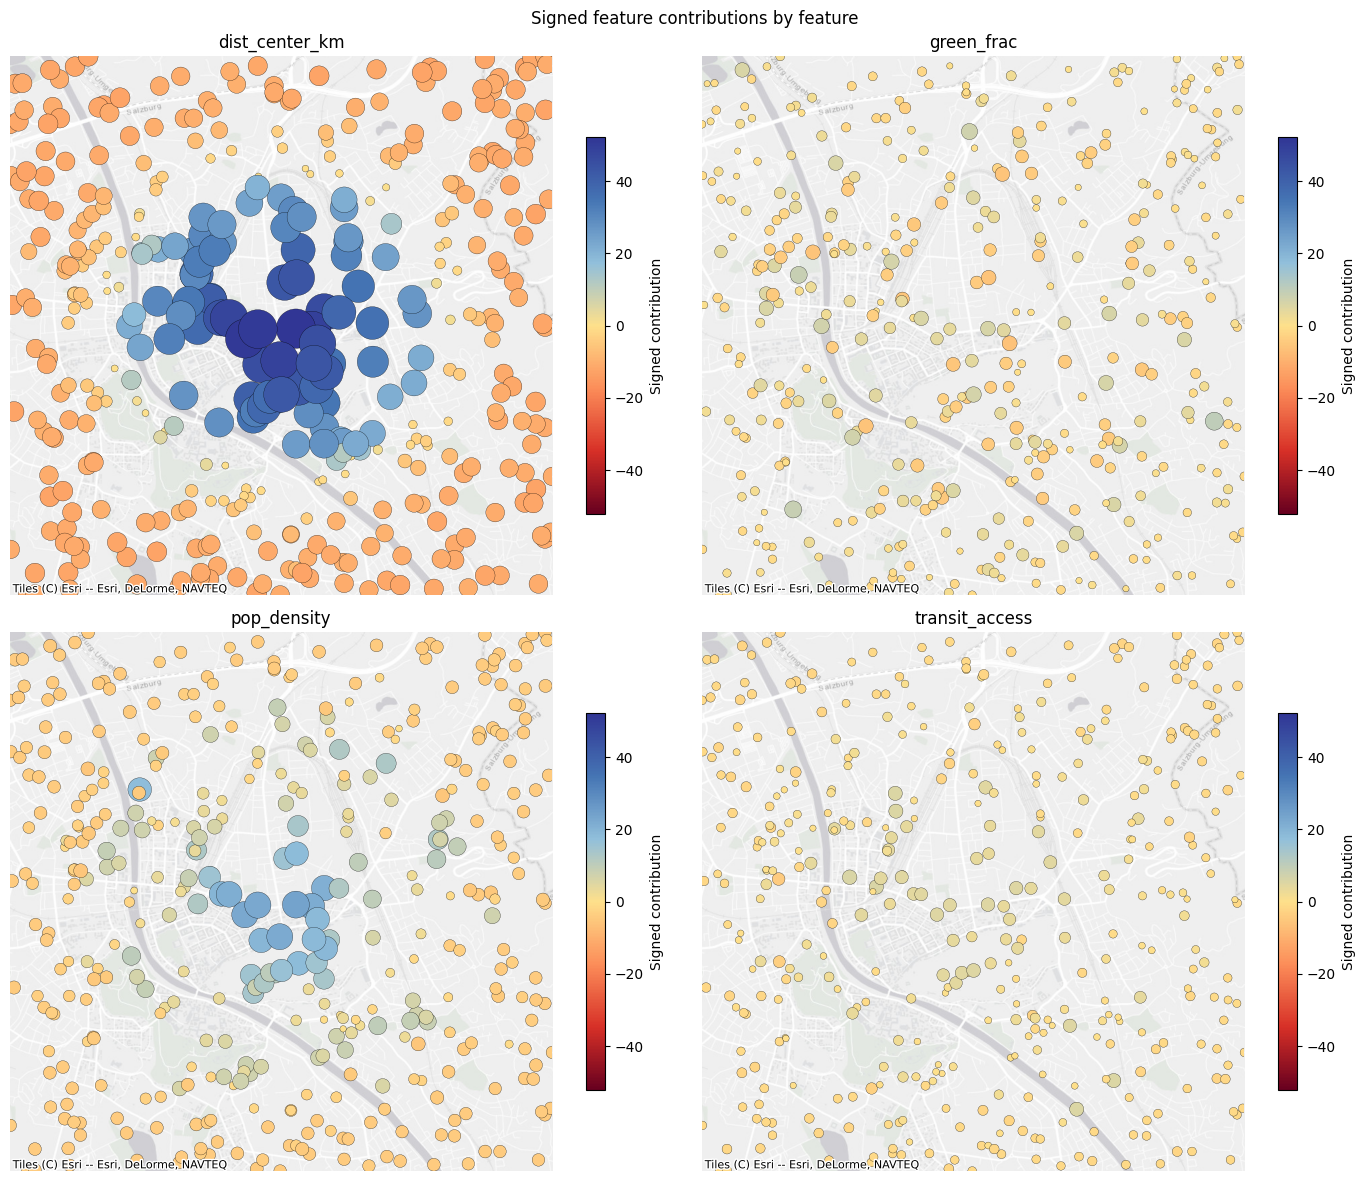

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12))  # Create one panel per feature.
map_xlim = (xs.min(), xs.max())  # Use the same horizontal extent in every panel.
map_ylim = (ys.min(), ys.max())  # Use the same vertical extent in every panel.
# Use a red -> yellow -> blue diverging palette with no white midpoint.
max_abs = max(gdf[f"contrib_{feature}"].abs().max() for feature in feats)
midpoint = 0
signed_cmap = LinearSegmentedColormap.from_list(
    "red_yellow_blue_no_white",
    ["#67001f", "#d73027", "#fc8d59", "#fee08b", "#91bfdb", "#4575b4", "#313695"],
)
for ax, feature in zip(axes.flat, feats):  # Draw each feature in its own panel.
    contribution = gdf[f"contrib_{feature}"]  # Keep the signed feature contribution.
    sc = ax.scatter(
        gdf.geometry.x,
        gdf.geometry.y,
        s=20 + 15 * contribution.abs(),
        c=contribution,
        cmap=signed_cmap,
        vmin=-max_abs,
        vmax=max_abs,
        edgecolor="k",
        linewidth=0.2,
        zorder=3,
    )  # Draw points with a signed diverging scale.
    ctx.add_basemap(ax, crs=gdf.crs, source=BASEMAP_SOURCE)  # Add the Salzburg basemap.
    ax.set_xlim(map_xlim)  # Apply the shared horizontal extent.
    ax.set_ylim(map_ylim)  # Apply the shared vertical extent.
    ax.set_title(feature)  # Label the feature panel.
    ax.set_axis_off()  # Hide coordinate axes.
    plt.colorbar(sc, ax=ax, label="Signed contribution", shrink=0.7)  # Explain the diverging color scale.
plt.suptitle("Signed feature contributions by feature")  # Add an overall title.

plt.tight_layout()  # Arrange the panels neatly.
plt.show()  # Display the four maps.

## 7. Map Type 1b — Proportional symbols (size = magnitude, colour = direction)

Each panel shows one feature's contribution as a true proportional symbol: the symbol **area** scales with the absolute contribution, shared across all four panels. Colour only encodes direction: blue = the feature increases demand, red = it decreases demand.

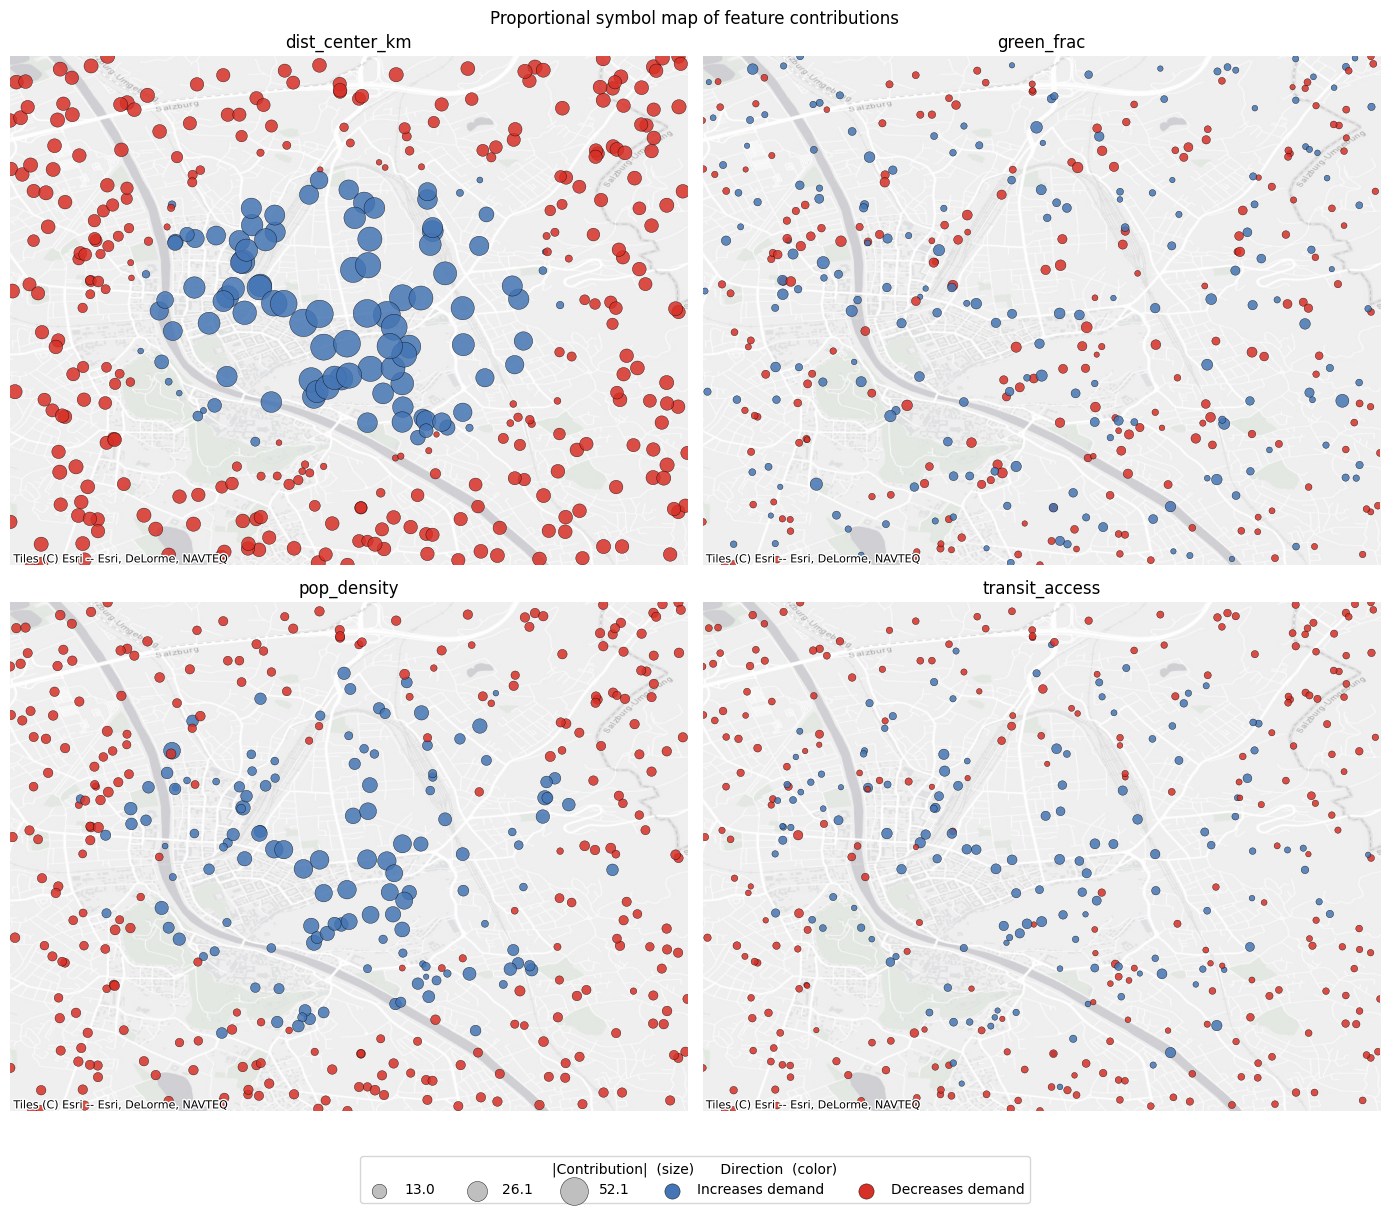

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12))  # Create one panel per feature.
map_xlim = (xs.min(), xs.max())  # Use the same horizontal extent in every panel.
map_ylim = (ys.min(), ys.max())  # Use the same vertical extent in every panel.
max_abs = max(gdf[f"contrib_{feature}"].abs().max() for feature in feats)  # Share one magnitude scale across panels.

# True proportional symbols: marker AREA (matplotlib's `s`) scales with |contribution|.
size_min, size_max = 15, 400  # Smallest and largest marker areas, in points^2.
def sizes_for(values):
    magnitude = np.abs(np.asarray(values))  # Only the magnitude drives symbol size.
    return size_min + (size_max - size_min) * (magnitude / max_abs)  # Linear area scaling, shared across panels.

pos_color, neg_color = "#4575b4", "#d73027"  # Two-color categorical scheme: blue = increases demand, red = decreases demand.

for ax, feature in zip(axes.flat, feats):  # Draw each feature in its own panel.
    contribution = gdf[f"contrib_{feature}"]  # Keep the signed feature contribution.
    colors = np.where(contribution >= 0, pos_color, neg_color)  # Encode direction (sign) with two flat colors.
    ax.scatter(
        gdf.geometry.x,
        gdf.geometry.y,
        s=sizes_for(contribution),
        c=colors,
        edgecolor="k",
        linewidth=0.3,
        alpha=0.85,
        zorder=3,
    )  # Draw proportional symbols: size = magnitude, color = direction.
    ctx.add_basemap(ax, crs=gdf.crs, source=BASEMAP_SOURCE)  # Add the Salzburg basemap.
    ax.set_xlim(map_xlim)  # Apply the shared horizontal extent.
    ax.set_ylim(map_ylim)  # Apply the shared vertical extent.
    ax.set_title(feature)  # Label the feature panel.
    ax.set_axis_off()  # Hide coordinate axes.

# Build ONE shared legend for the whole figure (a per-panel colorbar can't explain symbol size).
legend_magnitudes = np.array([0.25, 0.5, 1.0]) * max_abs  # Three representative |contribution| values.
size_handles = [
    plt.scatter([], [], s=float(sizes_for(v)), facecolor="0.75", edgecolor="k", linewidth=0.3, label=f"{v:.1f}")
    for v in legend_magnitudes
]  # Proxy points showing what each symbol size means.
color_handles = [
    plt.scatter([], [], s=120, facecolor=pos_color, edgecolor="k", linewidth=0.3, label="Increases demand"),
    plt.scatter([], [], s=120, facecolor=neg_color, edgecolor="k", linewidth=0.3, label="Decreases demand"),
]  # Proxy points showing what each color means.

fig.legend(
    handles=size_handles + color_handles,
    labels=[h.get_label() for h in size_handles] + [h.get_label() for h in color_handles],
    title="|Contribution|  (size)      Direction  (color)",
    loc="lower center",
    ncol=5,
    frameon=True,
    bbox_to_anchor=(0.5, -0.02),
)  # Explain both the proportional symbol sizes and the color-coded direction.

plt.suptitle("Proportional symbol map of feature contributions")  # Add an overall title.
plt.tight_layout(rect=[0, 0.05, 1, 1])  # Arrange panels, leaving room for the shared legend.
plt.show()  # Display the four maps.

## 8. Map Type 2 — Signed contribution grids (choropleth)

Each panel aggregates one feature's contribution into a 5×5 grid (mean per cell; empty cells are not drawn). The same red → yellow → blue scale as Map 1a is used: red cells mean the feature lowers demand in that area, blue cells mean it raises demand, and darker shades mean a larger effect.

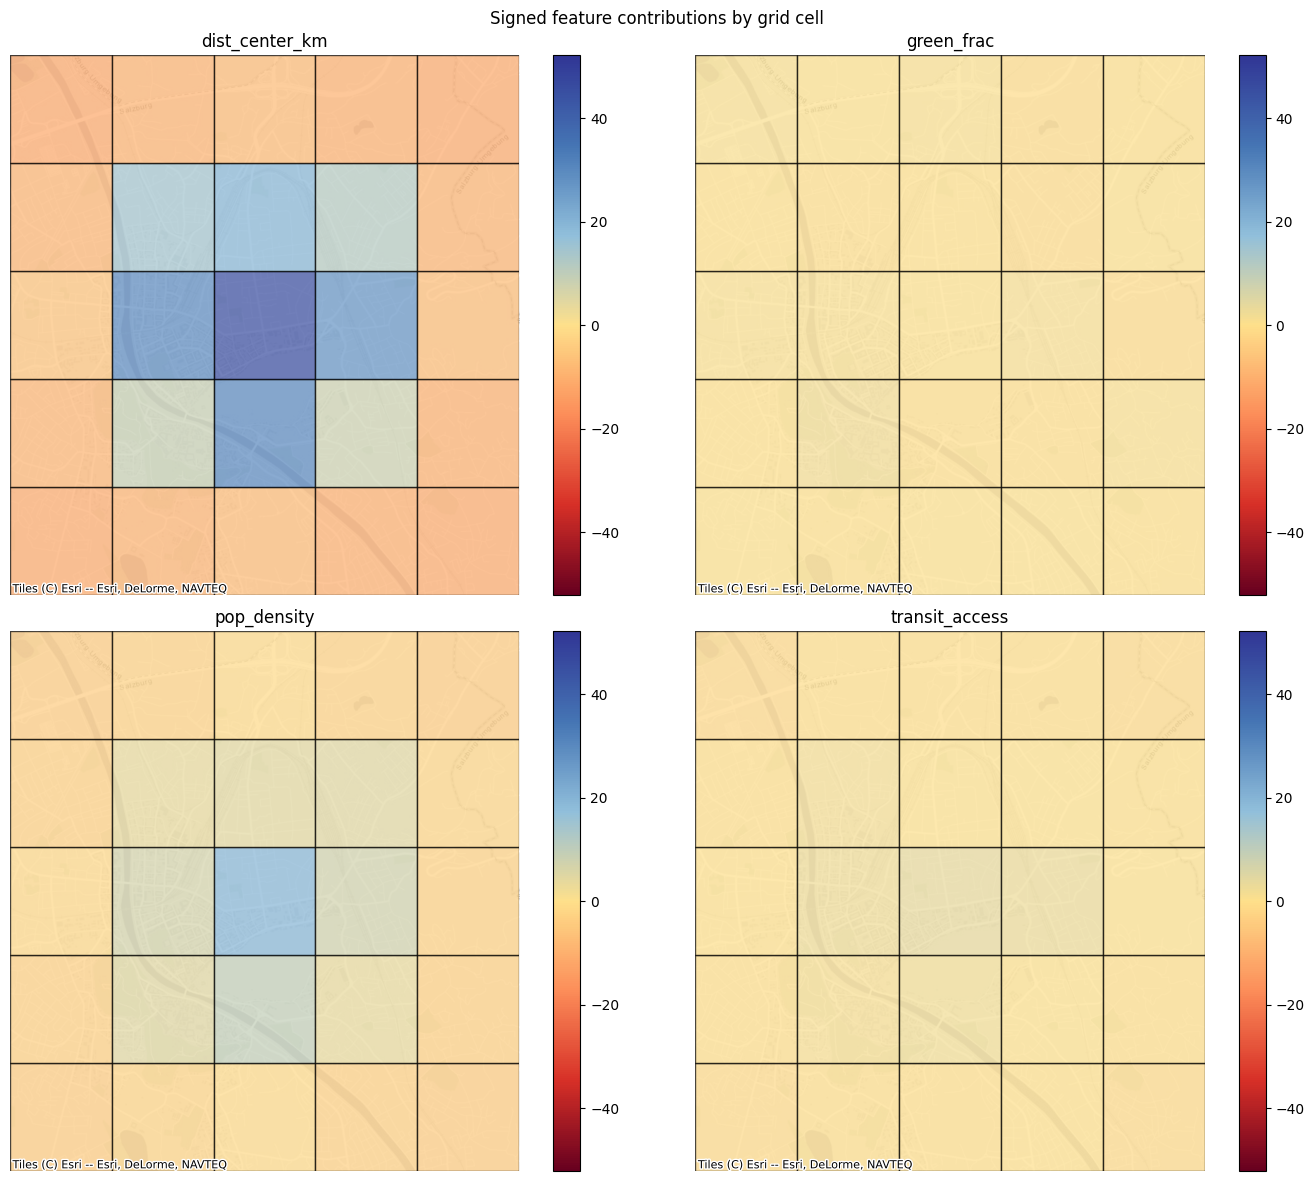

In [13]:
n_bins = 5  # Divide the study area into five bins per direction.
xs, ys = gdf.geometry.x, gdf.geometry.y  # Extract projected coordinates.
x_edges = np.linspace(xs.min(), xs.max(), n_bins + 1)  # Create horizontal bin edges.
y_edges = np.linspace(ys.min(), ys.max(), n_bins + 1)  # Create vertical bin edges.
gdf["x_bin"] = pd.cut(xs, x_edges, labels=False, include_lowest=True)  # Assign each point to a column.
gdf["y_bin"] = pd.cut(ys, y_edges, labels=False, include_lowest=True)  # Assign each point to a row.
max_abs = max(gdf[f"contrib_{feature}"].abs().max() for feature in feats)  # Use a symmetric shared scale for signed contributions.

fig, axes = plt.subplots(2, 2, figsize=(14, 12))  # Create one panel per feature.
for ax, feature in zip(axes.flat, feats):  # Build one grid for each feature.
    values = gdf.groupby(["y_bin", "x_bin"])[f"contrib_{feature}"].mean()  # Average the signed contribution in each cell.
    polys, contributions = [], []  # Prepare cell geometries and values.
    for (y_bin, x_bin), value in values.items():  # Visit each occupied cell.
        polys.append(box(x_edges[x_bin], y_edges[y_bin], x_edges[x_bin + 1], y_edges[y_bin + 1]))  # Create the rectangle.
        contributions.append(value)  # Store the signed cell contribution.
    grid = gpd.GeoDataFrame({"contribution": contributions}, geometry=polys, crs=gdf.crs)  # Build the feature grid.
    grid.plot(ax=ax, column="contribution", cmap=signed_cmap, vmin=-max_abs, vmax=max_abs, edgecolor="k", alpha=0.7, legend=True, zorder=3)  # Draw grids with the red-yellow-blue diverging scale.
    ctx.add_basemap(ax, crs=gdf.crs, source=BASEMAP_SOURCE)  # Add the Salzburg basemap.
    ax.set_xlim(xs.min(), xs.max())  # Apply the shared horizontal extent.
    ax.set_ylim(ys.min(), ys.max())  # Apply the shared vertical extent.
    ax.set_title(feature)  # Label the feature panel.
    ax.set_axis_off()  # Hide coordinate axes.
plt.suptitle("Signed feature contributions by grid cell")  # Add an overall title.
plt.tight_layout()  # Arrange the panels neatly.
plt.show()  # Display the four maps.

## 9. Map Type 3 — Interpolated signed contribution surfaces

Each panel interpolates one feature's contribution over space (cubic interpolation; areas outside the convex hull of the points stay empty). The same red → yellow → blue scale is used: red areas indicate the feature reduces demand, blue areas indicate it increases demand, and darker shades mean a larger effect. Note that interpolation produces values *between* observed points — patterns there are created by the method, not observed in the data.

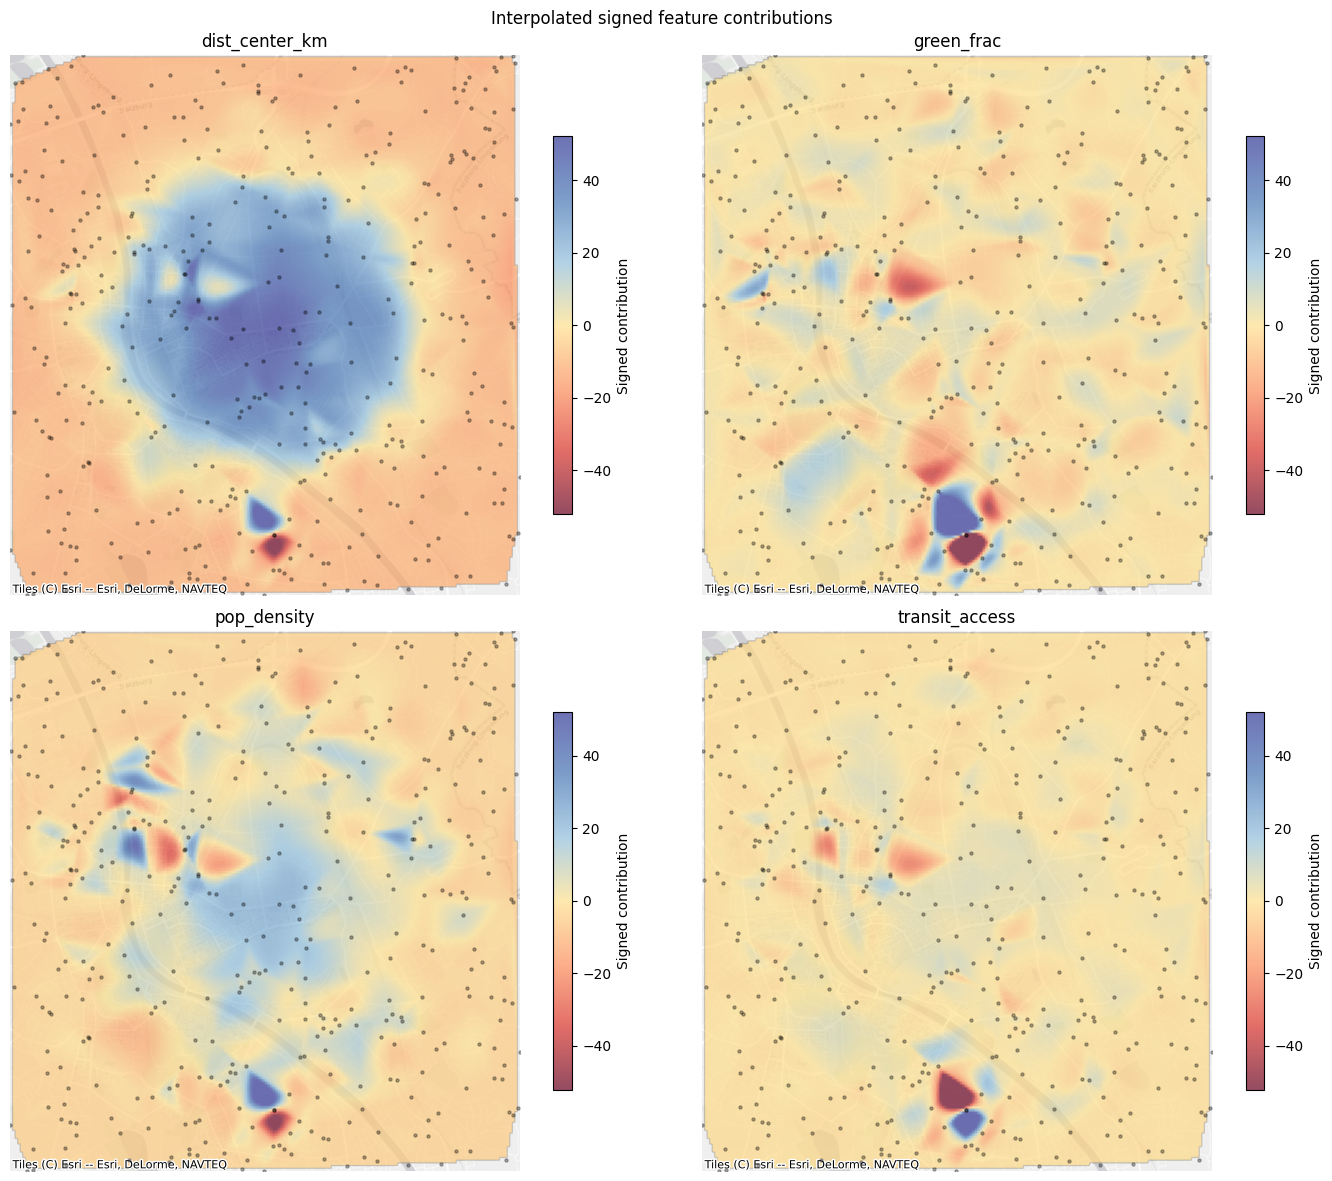

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12))  # Create one panel per feature.
max_abs = max(gdf[f"contrib_{feature}"].abs().max() for feature in feats)  # Use a symmetric shared scale for signed contributions.
for ax, feature in zip(axes.flat, feats):  # Interpolate each feature separately.
    values = gdf[f"contrib_{feature}"]  # Keep the signed contribution.
    grid_x, grid_y = np.mgrid[xs.min():xs.max():200j, ys.min():ys.max():200j]  # Create a fine interpolation grid.
    surface = griddata((xs, ys), values, (grid_x, grid_y), method="cubic")  # Interpolate the signed contribution field.
    im = ax.imshow(surface.T, extent=(xs.min(), xs.max(), ys.min(), ys.max()), origin="lower", cmap=signed_cmap, vmin=-max_abs, vmax=max_abs, alpha=0.7, zorder=3)  # Draw surfaces with the red-yellow-blue diverging scale.
    ax.scatter(xs, ys, s=5, c="k", alpha=0.3, zorder=4)  # Show the original locations.
    ctx.add_basemap(ax, crs=gdf.crs, source=BASEMAP_SOURCE)  # Add the Salzburg basemap.
    ax.set_xlim(xs.min(), xs.max())  # Apply the shared horizontal extent.
    ax.set_ylim(ys.min(), ys.max())  # Apply the shared vertical extent.
    ax.set_title(feature)  # Label the feature panel.
    ax.set_axis_off()  # Hide coordinate axes.
    plt.colorbar(im, ax=ax, label="Signed contribution", shrink=0.7)  # Explain the diverging color scale.
plt.suptitle("Interpolated signed feature contributions")  # Add an overall title.
plt.tight_layout()  # Arrange the panels neatly.
plt.show()  # Display the four maps.

## 10. Map Type 4 — Prediction, confidence, and feature importance

The first map shows predicted demand with confidence encoded alongside it: low-confidence points are faded (transparency). The second map shows confidence on its own. The third panel compares the average contribution magnitude of all four features.

Confidence is derived from the disagreement between the 200 trees (standard deviation of their predictions), rescaled to 0–1 *relative* to this dataset. It is computed on the training points, so it describes model disagreement, not true out-of-sample error.

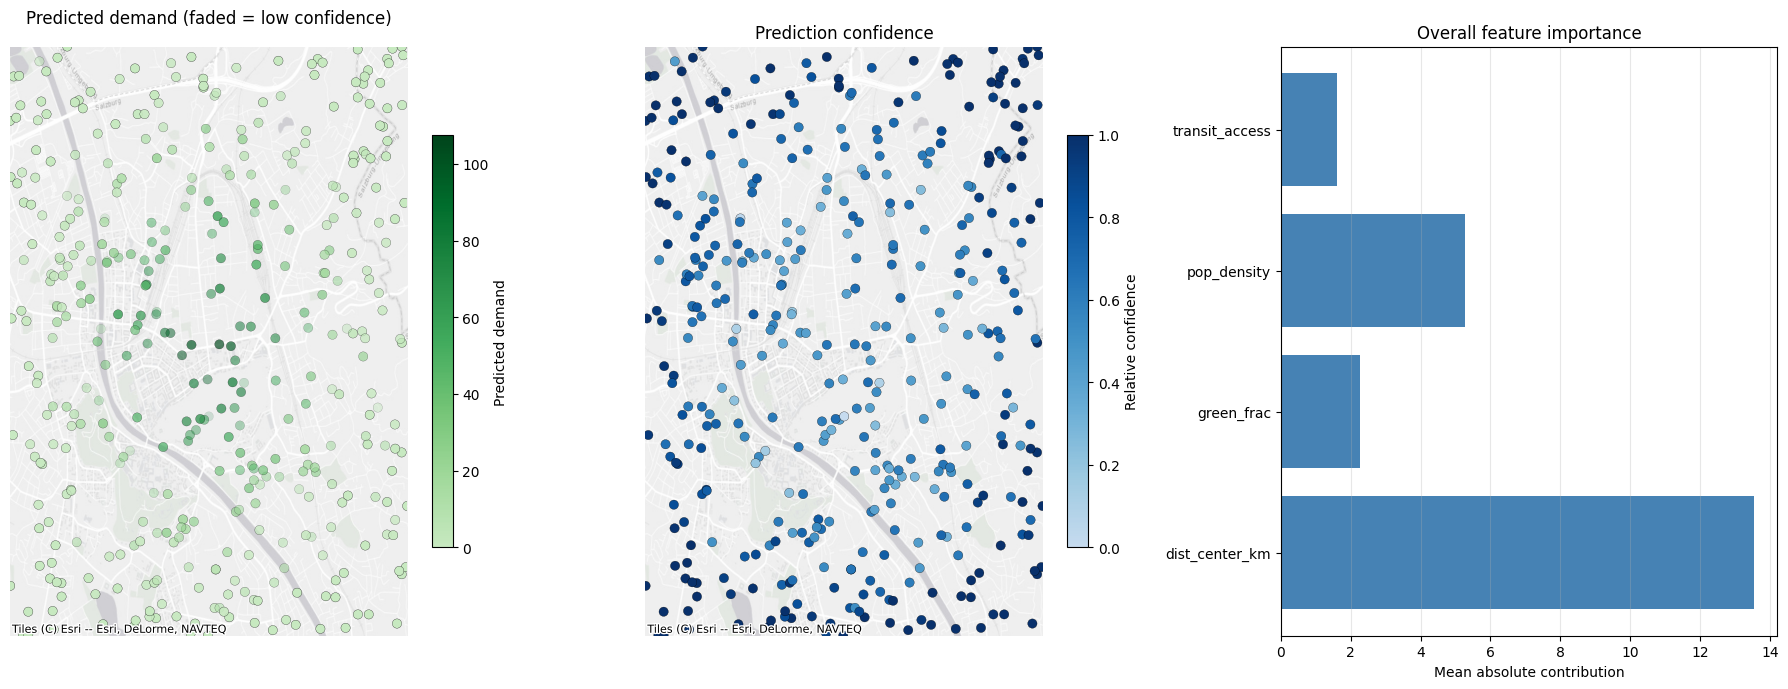

In [15]:
X = gdf[feats].to_numpy()  # Convert features to a plain NumPy array.
tree_preds = np.stack([tree.predict(X) for tree in model.estimators_], axis=1)  # Collect every tree prediction.
pred_mean = tree_preds.mean(axis=1)  # Calculate the average prediction.
pred_std = tree_preds.std(axis=1)  # Calculate prediction uncertainty.
confidence = 1 - (pred_std - pred_std.min()) / (pred_std.max() - pred_std.min())  # Convert uncertainty to relative confidence.
point_alpha = 0.15 + 0.85 * confidence  # Fade low-confidence points (never fully invisible).
importance = [gdf[f"contrib_{feature}"].abs().mean() for feature in feats]  # Calculate average feature contributions.
map_xlim = (xs.min(), xs.max())  # Use the same horizontal extent in both maps.
map_ylim = (ys.min(), ys.max())  # Use the same vertical extent in both maps.
fig, axes = plt.subplots(1, 3, figsize=(18, 7))  # Create three comparison panels.

sc = axes[0].scatter(xs, ys, c=pred_mean, cmap=green_cmap, vmin=demand_vmin, vmax=demand_vmax, alpha=point_alpha, s=45, edgecolor="k", linewidth=0.2, zorder=3)  # Demand colour + confidence as transparency.
ctx.add_basemap(axes[0], crs=gdf.crs, source=BASEMAP_SOURCE)  # Add the basemap to the demand map.
axes[0].set_xlim(map_xlim)  # Apply the shared horizontal extent.
axes[0].set_ylim(map_ylim)  # Apply the shared vertical extent.
plt.colorbar(sc, ax=axes[0], label="Predicted demand", shrink=0.7)  # Explain the demand colors.
axes[0].set_title("Predicted demand (faded = low confidence)")  # Label the first panel.
axes[0].set_axis_off()  # Hide coordinate axes.

sc = axes[1].scatter(xs, ys, c=confidence, cmap=blue_cmap, vmin=0, vmax=1, s=45, edgecolor="k", linewidth=0.2, zorder=3)  # Color points by confidence with readable blues.
ctx.add_basemap(axes[1], crs=gdf.crs, source=BASEMAP_SOURCE)  # Add the basemap to the confidence map.
axes[1].set_xlim(map_xlim)  # Apply the shared horizontal extent.
axes[1].set_ylim(map_ylim)  # Apply the shared vertical extent.
plt.colorbar(sc, ax=axes[1], label="Relative confidence", shrink=0.7)  # Explain the confidence colors.
axes[1].set_title("Prediction confidence")  # Label the second panel.
axes[1].set_axis_off()  # Hide coordinate axes.

axes[2].barh(feats, importance, color="steelblue")  # Compare average contribution magnitudes.
axes[2].set_xlabel("Mean absolute contribution")  # Explain the bar lengths.
axes[2].set_title("Overall feature importance")  # Label the third panel.
axes[2].grid(axis="x", alpha=0.3)  # Make the bar lengths easier to compare.

plt.tight_layout()  # Arrange all panels neatly.
plt.show()  # Display the comparison.

## 10. Discussion questions (5 min, in pairs)

1. Now that streets and real landmarks are visible, does the choropleth or the proportional symbol map feel more "trustworthy" simply because of the added geographic context? Is that a legitimate reason to prefer one encoding?
2. Compare the four feature panels in Maps 1–3. Which feature has the strongest contribution, and does that vary by location or grid cell?
3. Look at the attribution surfaces against real Salzburg streets. Where does smooth interpolation cross features such as the river or a hillside that should act as a boundary?
4. In Map 4, how do predicted demand, prediction confidence, and overall feature importance tell different parts of the story?

## 11. Discussion questions (5 min, in pairs)

1. Compare the proportional symbol maps (Map 1a/1b) and the choropleth (Map 2). Do they suggest the same hotspot? Why might aggregation change the story?
2. Compare the four feature panels in Maps 1–3. Which feature has the strongest contribution, and does that vary by location or grid cell?
3. Where does the interpolated attribution surface (Map 3) risk implying more spatial structure than the data supports — especially across real features like the Salzach river or a hillside that should act as a boundary? (Remember: the data is synthetic and knows nothing about the river.)
4. In Map 4, does the basemap change how you interpret faded (low-confidence) points? How do predicted demand, confidence, and overall feature importance tell different parts of the story?
5. Now that streets and real landmarks are visible, does one map feel more "trustworthy" simply because of the added geographic context? Is that a legitimate reason to prefer one encoding?
6. Which of these maps would you lead with for a non-expert audience, and why?

## 12. From design to evidence: how do you know a map actually works?

Everything above assumes a particular encoding communicates the explanation or uncertainty well — but that is an empirical claim, testable with real users, not just a design choice.

**Case study:** Afifah, Keskin, Çöltekin & Krisp (2025), *An Exploratory Study Investigating Users' Understanding of Noise Model Uncertainties Utilising Webcam Eye Tracking*, ICA Advances in Cartography and GIScience. The study used webcam-based eye tracking (n=35) to test how people interpret uncertainty in road-traffic noise models, comparing two colour schemes across four task types (visual search, comparison, expectation-violation, decision-making).

Key findings relevant to today's maps:
- Task accuracy was nearly identical across two different colour schemes (94.29% vs 91.43%) — the specific encoding mattered less than expected once the legend clearly supported the task.
- When a location showed lower noise/uncertainty than participants *expected* (e.g., a busy train station shown as quiet), only 57% correctly attributed this to underlying model mechanics rather than distrusting the map — domain expectation strongly shapes how uncertainty gets read.
- Eye-tracking data quality itself varied sharply by device (desktop gaze-click accuracy 86.5% vs smartphone 63.25%), a reminder that testing methodology introduces its own uncertainty.

### Task — Design a mini user test (10 min, groups of 2–3)

Pick two of the maps you built above (e.g., Map 1b vs Map 4). Sketch a short user-test design, similar in spirit to the noise-model study:

1. What single task would you give a participant (e.g., "point to the location you'd trust least")?
2. What would you measure — accuracy, time-to-answer, gaze/click location, or a qualitative follow-up question?
3. What expectation bias might interfere with your results, the way the "quiet train station" surprised participants in the noise study?
4. Would you test experts (e.g., GIS students) or non-experts, and why might their answers differ?

## 13. Closing question

What makes a geovisualization *trustworthy* for you? There's no single correct answer — this is the same open question the case study above was designed to probe empirically rather than assume.


## Troubleshooting notes

**"API key required" watermark on every tile:** switch `BASEMAP_SOURCE` to a keyless provider such as `Esri.WorldStreetMap` or `OpenStreetMap.HOT`.

**Tiles fail to download:** use a different keyless basemap or check your internet connection.

**Feature-name warning:** `.to_numpy()` is used before predicting with the individual trees to avoid this warning.